In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/retail_customer_churn_100k (1).csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (100000, 18)


,customer_id,age_group,gender,region,customer_segment,preferred_channel,purchase_frequency,avg_order_value,total_spent,recency_days,website_visits,discount_usage_rate,email_open_rate,cart_abandonment_rate,loyalty_score,engagement_score,churn_risk,churn_flag
0,C000001,18-24,Other,North,Loyal,Online,5,381.27,2108.80,189,27,0.38,0.13,0.42,33,35.5,Medium,1
1,C000002,25-34,Other,South,New,Mobile App,12,376.65,3843.06,277,68,0.51,0.06,0.07,68,49.5,Medium,1
2,C000003,55+,Other,North,VIP,Online,5,37.73,224.65,271,23,0.64,0.22,0.46,73,38.0,High,1
3,C000004,18-24,Male,North,Returning,Mobile App,12,191.19,1960.79,89,93,0.66,0.31,0.13,93,59.0,Low,0
4,C000005,55+,Other,North,Returning,Mobile App,2,279.64,594.79,264,4,0.73,0.27,0.58,11,34.5,High,1


In [9]:
from pathlib import Path
import sys

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline

# Find the project root so the notebook works from either the root or notebooks/.
project_root = Path.cwd()
while not (project_root / "src").is_dir() and project_root.parent != project_root:
    project_root = project_root.parent
if not (project_root / "src").is_dir():
    raise FileNotFoundError("Could not locate the project root containing src/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import RANDOM_STATE, TEST_SIZE
from src.data_processor import prepare_model_data, split_features_target
from src.model_trainer import build_preprocessing_pipeline, get_models

model_df = prepare_model_data(df)
X, y = split_features_target(model_df)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

preprocessor = build_preprocessing_pipeline()
models = get_models()
pipelines = {}
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline(
        steps=[("preprocessor", preprocessor), ("model", model)]
    )
    pipeline.fit(X_train, y_train)
    pipelines[name] = pipeline
    trained_models[name] = pipeline
    print(f"Trained {name}.")

Trained Logistic Regression.
Trained Random Forest.
Trained Extra Trees.
Trained Gradient Boosting.
Trained XGBoost.


In [10]:
def evaluate_model(model, X_test, y_test):

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    return {
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Precision": precision_score(
            y_test,
            predictions
        ),

        "Recall": recall_score(
            y_test,
            predictions
        ),

        "F1 Score": f1_score(
            y_test,
            predictions
        ),

        "ROC-AUC": roc_auc_score(
            y_test,
            probabilities
        )
    }

In [11]:
results = []

for name, model in trained_models.items():

    metrics = evaluate_model(
        model,
        X_test,
        y_test
    )

    metrics["Model"] = name

    results.append(metrics)

results_df = pd.DataFrame(results)

results_df = results_df[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ]
]

results_df.sort_values(
    "ROC-AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.94590,0.941864,0.941049,0.941457,0.990379
3,Gradient Boosting,0.94500,0.940794,0.940184,0.940489,0.989848
4,XGBoost,0.94405,0.939623,0.939319,0.939471,0.989813
1,Random Forest,0.94205,0.937933,0.936614,0.937273,0.988313
2,Extra Trees,0.93885,0.938456,0.928610,0.933507,0.988191


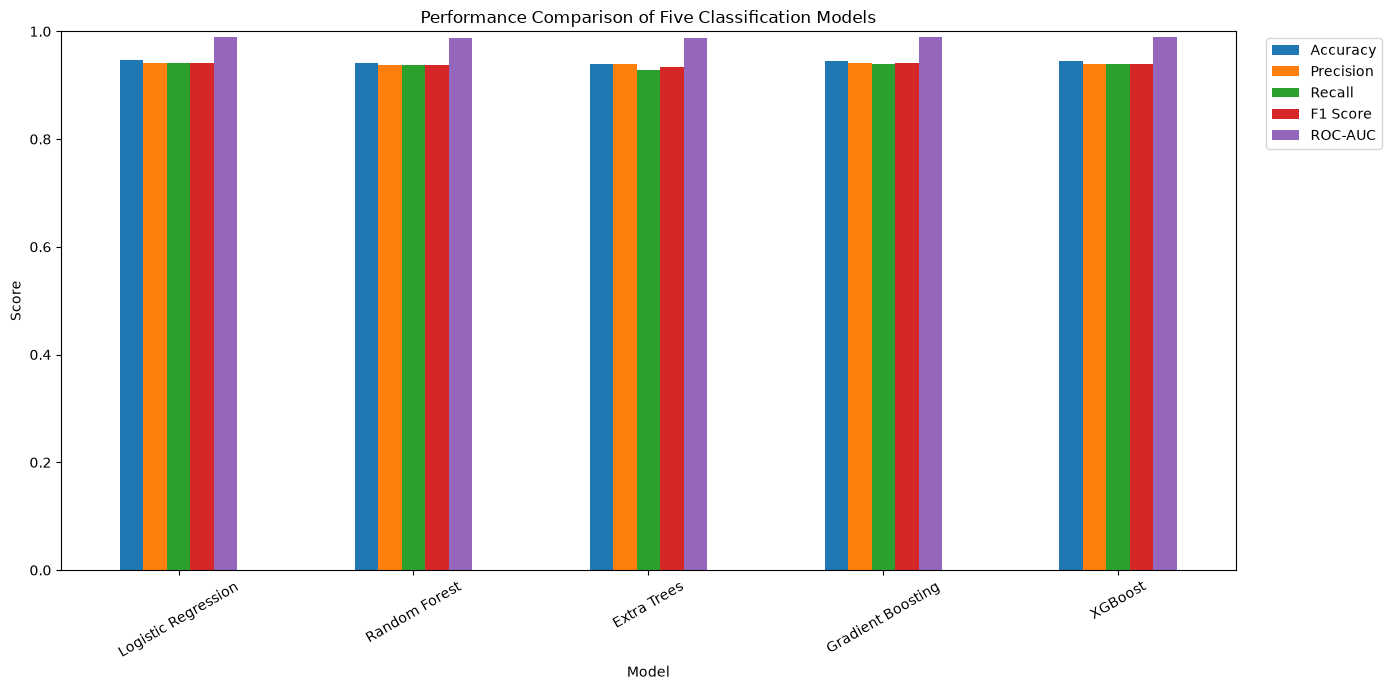

In [12]:
comparison = results_df.set_index("Model")

comparison.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Performance Comparison of Five Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=30)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

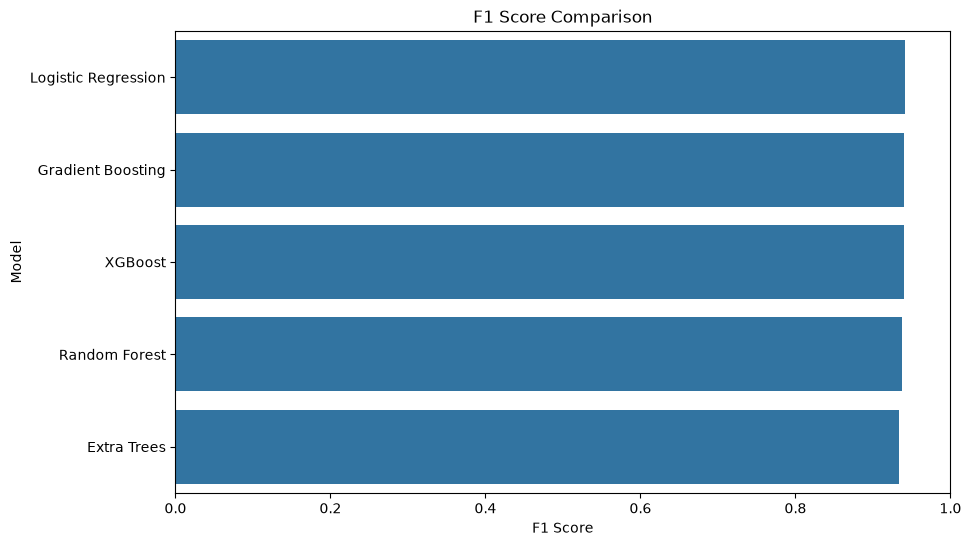

In [13]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df.sort_values(
        "F1 Score",
        ascending=False
    ),
    x="F1 Score",
    y="Model"
)

plt.title("F1 Score Comparison")
plt.xlim(0, 1)

plt.show()

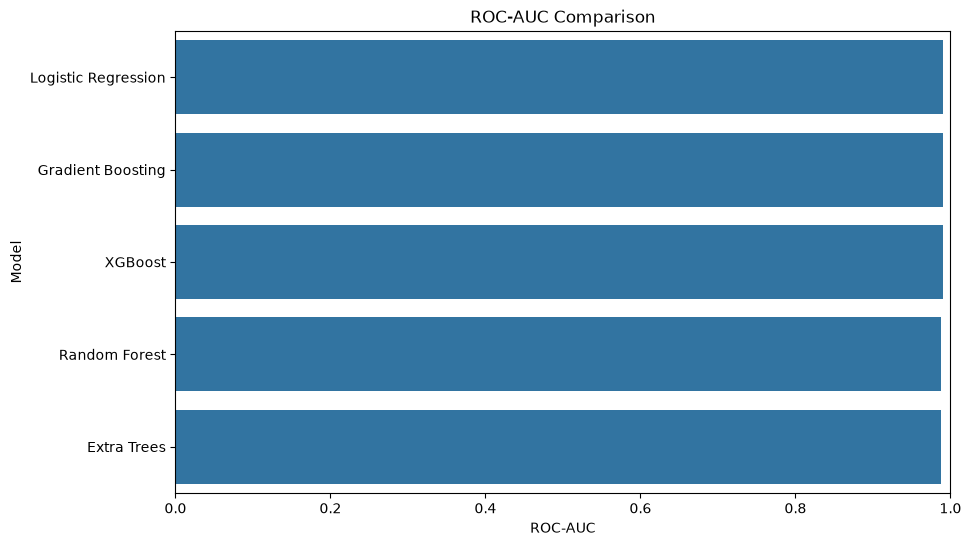

In [14]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df.sort_values(
        "ROC-AUC",
        ascending=False
    ),
    x="ROC-AUC",
    y="Model"
)

plt.title("ROC-AUC Comparison")
plt.xlim(0, 1)

plt.show()

In [15]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, pipeline in pipelines.items():

    print(f"Cross-validating: {name}")

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=[
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc"
        ],
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_df = pd.DataFrame(cv_results)

cv_df.sort_values(
    "CV ROC-AUC",
    ascending=False
)

Cross-validating: Logistic Regression
Cross-validating: Random Forest
Cross-validating: Extra Trees
Cross-validating: Gradient Boosting
Cross-validating: XGBoost


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
0,Logistic Regression,0.94438,0.939769,0.939923,0.939843,0.990262
4,XGBoost,0.94279,0.937526,0.938798,0.938159,0.989696
3,Gradient Boosting,0.94341,0.938500,0.939122,0.938808,0.989682
1,Random Forest,0.94052,0.936391,0.934839,0.935609,0.988124
2,Extra Trees,0.93887,0.937743,0.929474,0.933583,0.987985


In [16]:
final_comparison = results_df.merge(
    cv_df,
    on="Model"
)

final_comparison.sort_values(
    "CV ROC-AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
0,Logistic Regression,0.94590,0.941864,0.941049,0.941457,0.990379,0.94438,0.939769,0.939923,0.939843,0.990262
4,XGBoost,0.94405,0.939623,0.939319,0.939471,0.989813,0.94279,0.937526,0.938798,0.938159,0.989696
3,Gradient Boosting,0.94500,0.940794,0.940184,0.940489,0.989848,0.94341,0.938500,0.939122,0.938808,0.989682
1,Random Forest,0.94205,0.937933,0.936614,0.937273,0.988313,0.94052,0.936391,0.934839,0.935609,0.988124
2,Extra Trees,0.93885,0.938456,0.928610,0.933507,0.988191,0.93887,0.937743,0.929474,0.933583,0.987985


In [17]:
best_model_name = (
    final_comparison
    .sort_values(
        "CV ROC-AUC",
        ascending=False
    )
    .iloc[0]["Model"]
)

best_model = trained_models[
    best_model_name
]

y_pred = best_model.predict(X_test)

print("Best Model:")
print(best_model_name)

Best Model:
Logistic Regression


In [18]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Churn",
            "Churn"
        ]
    )
)

              precision    recall  f1-score   support

    No Churn       0.95      0.95      0.95     10755
       Churn       0.94      0.94      0.94      9245

    accuracy                           0.95     20000
   macro avg       0.95      0.95      0.95     20000
weighted avg       0.95      0.95      0.95     20000



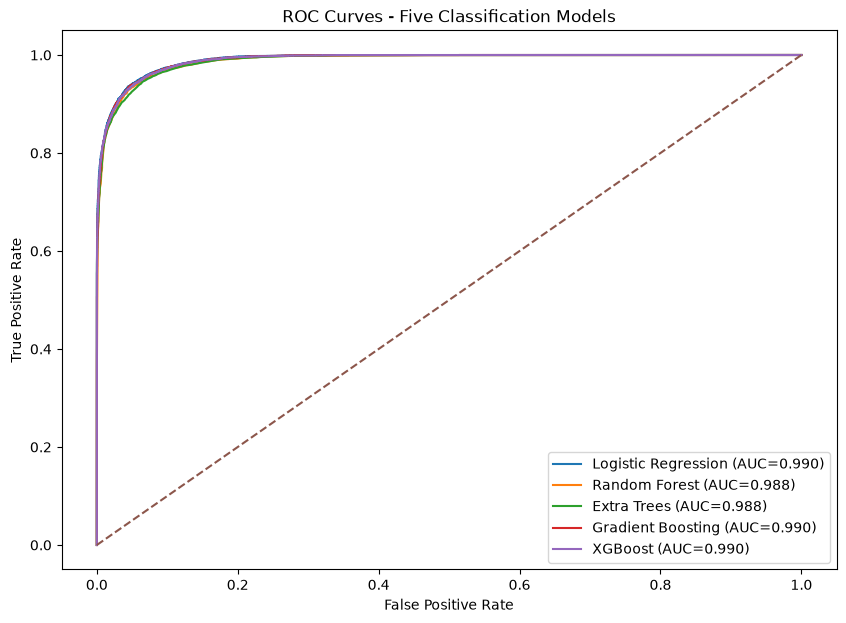

In [19]:
plt.figure(figsize=(10, 7))

for name, model in trained_models.items():

    probabilities = model.predict_proba(
        X_test
    )[:, 1]

    from sklearn.metrics import roc_curve

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curves - Five Classification Models")

plt.legend()

plt.show()